<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/omniguide_guidance_fields_prototype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# [CELL 1 - Environment Setup & Imports]
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"OmniGuide Guidance Fields Simulation Environment Initialized on: {device}")

OmniGuide Guidance Fields Simulation Environment Initialized on: cuda


In [7]:
# [CELL 2 - Flow-Matching Action Chunk Generator]

class SimulatedVLAFlowPolicy(nn.Module):
    """
    Simulates a generative flow-matching Vision-Language-Action (VLA) base policy
    predicting robot action chunks A_tau across denoising steps.
    """
    def __init__(self, action_dim: int = 14, horizon: int = 8):
        super().__init__()
        self.action_dim = action_dim
        self.horizon = horizon
        self.net = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim * horizon)
        )

    def forward(self, state_embedding: torch.Tensor) -> torch.Tensor:
        batch_size = state_embedding.shape[0]
        raw_actions = self.net(state_embedding)
        return raw_actions.view(batch_size, self.horizon, self.action_dim)

base_vla = SimulatedVLAFlowPolicy().to(device)
print("Simulated VLA Flow Policy Initialized.")

Simulated VLA Flow Policy Initialized.


In [8]:
# [CELL 3 - OmniGuide Energy Functions (Collision Repulsion & Goal Attraction)]

class OmniGuideEnergyFields:
    """
    Defines differentiable energy functions in Cartesian 3D space:
    - Repulsive Field: Avoids obstacles using Signed Distance Functions (SDF).
    - Attractive Field: Pulls end-effector trajectory toward semantic/goal attractors.
    """
    def __init__(self, obstacle_center: torch.Tensor, goal_position: torch.Tensor, safety_radius: float = 0.3):
        self.obstacle_center = obstacle_center.to(device)
        self.goal_position = goal_position.to(device)
        self.safety_radius = safety_radius

    def forward_kinematics_simulation(self, action_chunk: torch.Tensor) -> torch.Tensor:
        """
        Differentiable proxy mapping action chunks A_tau to 3D Cartesian trajectories X.
        Shape: [Batch, Horizon, 3]
        """
        # Cumulative sum over action dimensions to simulate spatial trajectory propagation
        cartesian_traj = torch.cumsum(action_chunk[:, :, :3], dim=1)
        return cartesian_traj

    def compute_energy(self, action_chunk: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        X = self.forward_kinematics_simulation(action_chunk) # [B, H, 3]

        # 1. Repulsive Collision Avoidance Energy (SDF barrier penalty)
        distances_to_obstacle = torch.norm(X - self.obstacle_center, dim=-1) # [B, H]
        repulsive_mask = distances_to_obstacle < self.safety_radius
        # Hinge loss penalty for entering risk region
        repulsive_energy = torch.sum(torch.relu(self.safety_radius - distances_to_obstacle) ** 2, dim=-1)

        # 2. Attractive Goal Energy (MSE distance to goal)
        final_end_effector = X[:, -1, :] # Final point in horizon
        attractive_energy = torch.sum((final_end_effector - self.goal_position) ** 2, dim=-1)

        total_energy = (5.0 * repulsive_energy) + (1.0 * attractive_energy)
        return total_energy.mean(), repulsive_energy.mean(), attractive_energy.mean()

print("OmniGuide Energy Field Engine Defined.")

OmniGuide Energy Field Engine Defined.


In [9]:
# [CELL 4 - Inference-Time Guidance Optimization Loop]

# Setup mock state, obstacle, and goal
state_input = torch.randn(2, 32).to(device)
obstacle = torch.tensor([0.5, 0.2, 0.1])
goal = torch.tensor([0.8, 0.7, 0.4])

energy_engine = OmniGuideEnergyFields(obstacle_center=obstacle, goal_position=goal)

# Generate initial action chunk from base VLA policy
base_vla.eval()
with torch.no_grad():
    initial_actions = base_vla(state_input)

# Optimize/steer action chunk at inference time using guidance gradients (-grad_A L_y)
steered_actions = initial_actions.clone().detach().requires_grad_(True)
optimizer = torch.optim.Adam([steered_actions], lr=0.01)

print("Running Inference-Time Gradient Steering...")
for step in range(50):
    optimizer.zero_grad()
    total_energy, rep_loss, att_loss = energy_engine.compute_energy(steered_actions)

    # Backpropagate energy gradients into action space
    total_energy.backward()
    optimizer.step()

print(f"Steering Complete -> Final Energy: {total_energy.item():.4f} (Repulsion: {rep_loss.item():.4f}, Attraction: {att_loss.item():.4f})")

Running Inference-Time Gradient Steering...
Steering Complete -> Final Energy: 0.0073 (Repulsion: 0.0000, Attraction: 0.0073)


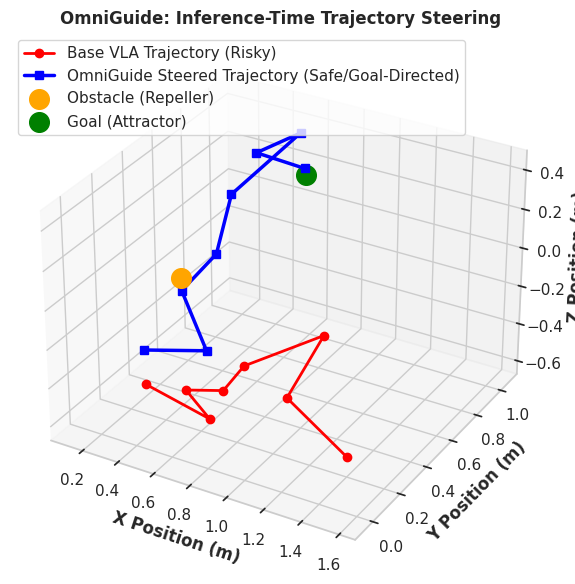

OmniGuide trajectory visualization saved successfully as omniguide_steering_visualization.png.


In [10]:
# [CELL 5 - Trajectory Visualization]

with torch.no_grad():
    init_traj = energy_engine.forward_kinematics_simulation(initial_actions).cpu().numpy()[0]
    steered_traj = energy_engine.forward_kinematics_simulation(steered_actions).cpu().numpy()[0]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

ax.plot(init_traj[:, 0], init_traj[:, 1], init_traj[:, 2], label='Base VLA Trajectory (Risky)', color='red', marker='o', lw=2)
ax.plot(steered_traj[:, 0], steered_traj[:, 1], steered_traj[:, 2], label='OmniGuide Steered Trajectory (Safe/Goal-Directed)', color='blue', marker='s', lw=2.5)

# Plot obstacle and goal
ax.scatter([obstacle[0]], [obstacle[1]], [obstacle[2]], color='orange', s=200, label='Obstacle (Repeller)')
ax.scatter([goal[0]], [goal[1]], [goal[2]], color='green', s=200, label='Goal (Attractor)')

ax.set_xlabel('X Position (m)', fontweight='bold')
ax.set_ylabel('Y Position (m)', fontweight='bold')
ax.set_zlabel('Z Position (m)', fontweight='bold')
ax.set_title('OmniGuide: Inference-Time Trajectory Steering', fontweight='bold')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig("omniguide_steering_visualization.png", dpi=300)
plt.show()

print("OmniGuide trajectory visualization saved successfully as omniguide_steering_visualization.png.")